# Customer Segmentation using K-Means

## Project Overview

This project aims to segment customers into distinct groups based on their age, annual income, and spending score.

The K-Means clustering algorithm is used to identify customers with similar characteristics and purchasing behavior.

## Objectives

- Explore and understand the customer dataset.
- Perform exploratory data analysis.
- Apply K-Means clustering.
- Determine customer segments.
- Analyze the characteristics of each segment.
- Extract useful business insights.

## 1. Dataset

The dataset contains information about 200 customers.

The main variables are:

- **CustomerID**: Unique identifier for each customer.
- **Gender**: Customer gender.
- **Age**: Customer age.
- **Annual Income (k$)**: Annual income in thousands of dollars.
- **Spending Score (1-100)**: Score assigned based on customer spending behavior.

## 2. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 3. Load Dataset

In [2]:
df = pd.read_csv("../data/Mall_Customers.csv")

In [3]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 4. Exploratory Data Analysis

In this section, we explore the dataset and analyze the main characteristics of the customers.

In [4]:
df.shape

(200, 5)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


### 4.1 Missing Values

The dataset contains no missing values.

In [6]:
df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

### 4.2 Descriptive Statistics

The descriptive statistics provide an overview of the numerical variables in the dataset.

In [7]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


### 4.3 Gender Distribution

This section shows the distribution of customers by gender.

In [8]:
df["Gender"].value_counts()

Gender
Female    112
Male       88
Name: count, dtype: int64

### 4.4 Income vs Spending Score

The scatter plot shows the relationship between annual income and spending score.

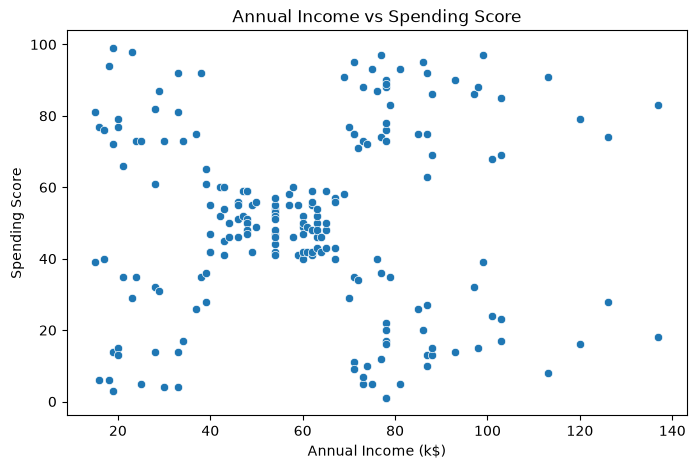

In [9]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)"
)

plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score")
plt.show()

## 5. K-Means Clustering

K-Means is an unsupervised machine learning algorithm used to divide customers into groups based on similar characteristics.

In this project, we use annual income and spending score to segment customers.

In [18]:
from sklearn.cluster import KMeans

X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

### 5.1 Elbow Method

The Elbow Method is used to determine an appropriate number of clusters for the K-Means algorithm.

C:\Users\DELL\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\DELL\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\DELL\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\DELL\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows wi

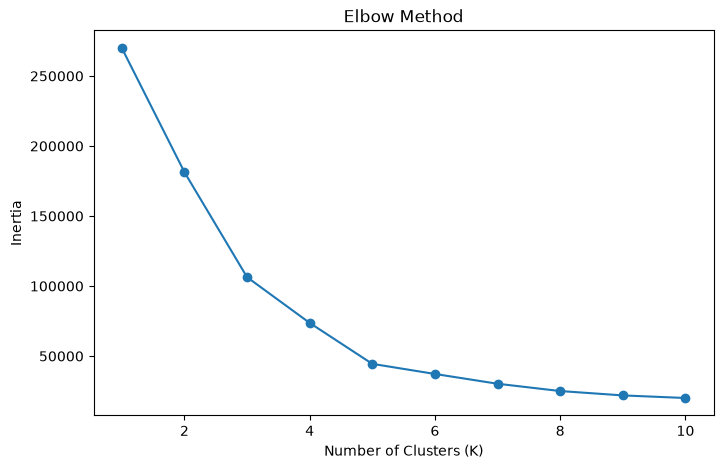

In [19]:
inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.show()

### 5.2 Apply K-Means

Based on the Elbow Method, we use 5 clusters to segment the customers.

In [11]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

df["Cluster"] = kmeans.fit_predict(X)

df.head()

C:\Users\DELL\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4


### 5.3 Cluster Visualization

The following scatter plot visualizes the five customer segments based on annual income and spending score.

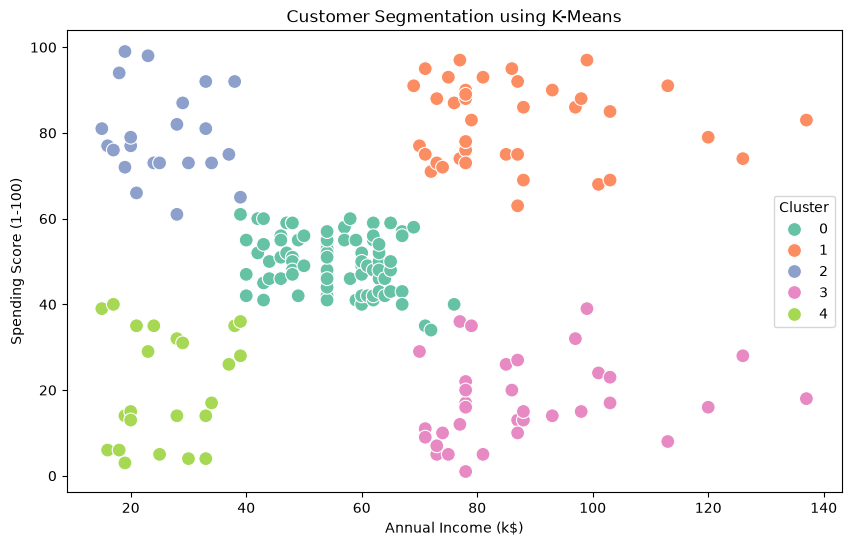

In [12]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="Set2",
    s=100
)

plt.title("Customer Segmentation using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.show()

## 6. Cluster Analysis

### 6.1 Number of Customers per Cluster

This section analyzes the size of each customer segment.

In [13]:
df.groupby("Cluster")[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].mean().round(2)

,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,42.72,55.30,49.52
1,32.69,86.54,82.13
2,25.27,25.73,79.36
3,41.11,88.20,17.11
4,45.22,26.30,20.91


In [14]:
df["Cluster"].value_counts().sort_index()

Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

### 6.2 Cluster Size Visualization

The bar chart shows the number of customers belonging to each cluster.

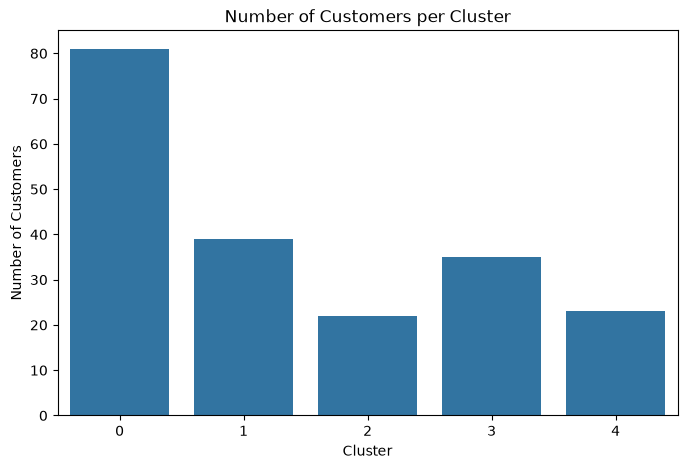

In [15]:
cluster_counts = df["Cluster"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=cluster_counts.index,
    y=cluster_counts.values
)

plt.title("Number of Customers per Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.show()

### 6.3 Cluster Profile

The following table summarizes the main characteristics of each customer cluster, including age, annual income, and spending score.

In [16]:
cluster_profile = df.groupby("Cluster").agg(
    Customers=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending=("Spending Score (1-100)", "mean")
).round(2)

cluster_profile

,Customers,Average_Age,Average_Income,Average_Spending
Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91


### 6.4 Cluster Centroids

The cluster centroids represent the average position of each customer segment based on annual income and spending score.

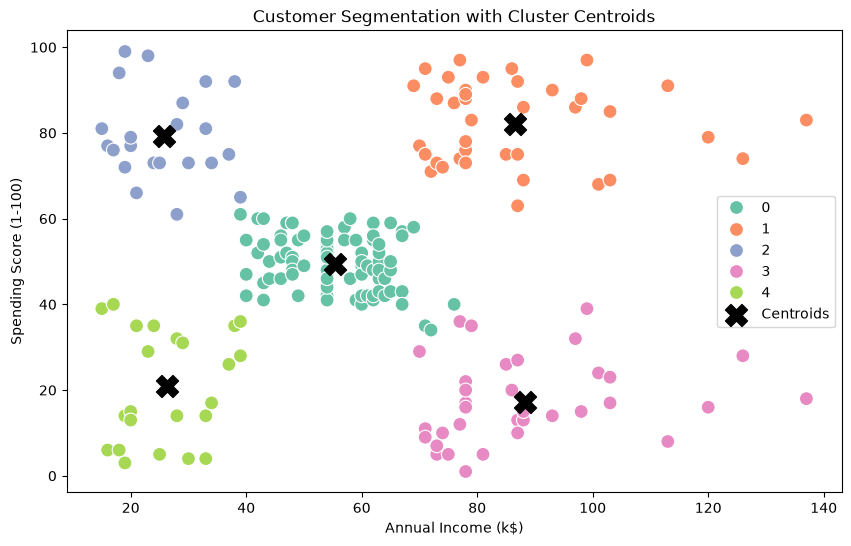

In [17]:
centers = kmeans.cluster_centers_

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="Set2",
    s=100
)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="X",
    s=250,
    color="black",
    label="Centroids"
)

plt.title("Customer Segmentation with Cluster Centroids")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.show()

## 7. Business Insights

The K-Means algorithm identified five distinct customer segments based on annual income and spending score.

- **Cluster 0:** Medium-income customers with a medium spending score. This is the largest customer segment.
- **Cluster 1:** High-income customers with a high spending score. These customers show strong purchasing behavior.
- **Cluster 2:** Low-income customers with a high spending score. Despite their lower income, these customers have a high spending score.
- **Cluster 3:** High-income customers with a low spending score. These customers may have potential for targeted marketing strategies.
- **Cluster 4:** Low-income customers with a low spending score. These customers show relatively low spending behavior.

## 8. Conclusion

In this project, K-Means clustering was used to segment customers based on annual income and spending score.

The analysis identified five customer segments with different characteristics.

The results show how unsupervised machine learning can be used to discover customer groups and support data-driven business analysis.

This project provided practical experience in data preprocessing, exploratory data analysis, data visualization, and machine learning.